In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'BBDC4.SA'
papeis_adicionais = ['BBAS3.SA', 'SANB11.SA', 'ITUB4.SA', 'BBDC3.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[BBDC4.SA] Cache existente cobre de 2020-01-02 a 2025-06-25.
[BBDC4.SA] Cache cobre período solicitado (2023-01-07 a 2025-06-25).
[BBDC4.SA] Retornando 613 linhas para o período solicitado.
⬇️ Baixando dados macro de 07/01/2022 a 26/06/2025...
Baixando série 432 (selic)...
Baixando série 433 (ipca)...
Baixando série 1 (dolar)...
💾 Dados salvos em cache: ../dados\macro_20220107_20250626.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-24.
[^BVSP] Cache NÃO cobre período solicitado. Download (total ou complementar) necessário.
[^BVSP] Iniciando download de dados (lógica de atualização/complemento)...
[^BVSP] Período de download yfinance: 2020-01-01 a 2025-06-26
YF.download() has changed argument auto_adjust default to True
Index(['data', 'close', 'high', 'low', 'open', 'volume'], dtype='object', name='Price')
[^BVSP] Realizando verificação de divergência entre cache antigo e dados frescos...
[^BVSP] Pós-Download Total: Nenhuma divergência significativa nas amostras (tolerância 1

,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_SANB11,adc_high_SANB11,adc_low_SANB11,adc_close_SANB11,adc_volume_SANB11,adc_pct_change_SANB11,adc_vol_SANB11,adc_rsi_SANB11,adc_macd_SANB11,adc_macd_signal_SANB11,adc_macd_hist_SANB11,adc_tr_SANB11,adc_atr_SANB11,adc_atr_pct_SANB11,adc_tr_pct_SANB11,adc_mm5_SANB11,adc_mm20_SANB11,adc_open_ITUB4,adc_high_ITUB4,adc_low_ITUB4,adc_close_ITUB4,adc_volume_ITUB4,adc_pct_change_ITUB4,adc_vol_ITUB4,adc_rsi_ITUB4,adc_macd_ITUB4,adc_macd_signal_ITUB4,adc_macd_hist_ITUB4,adc_tr_ITUB4,adc_atr_ITUB4,adc_atr_pct_ITUB4,adc_tr_pct_ITUB4,adc_mm5_ITUB4,adc_mm20_ITUB4,adc_open_BBDC3,adc_high_BBDC3,adc_low_BBDC3,adc_close_BBDC3,adc_volume_BBDC3,adc_pct_change_BBDC3,adc_vol_BBDC3,adc_rsi_BBDC3,adc_macd_BBDC3,adc_macd_signal_BBDC3,adc_macd_hist_BBDC3,adc_tr_BBDC3,adc_atr_BBDC3,adc_atr_pct_BBDC3,adc_tr_pct_BBDC3,adc_mm5_BBDC3,adc_mm20_BBDC3
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-06-11,15.770000,16.360001,15.650000,16.320000,48251000,0.030954,0.015763,68.281475,0.516125,0.618720,-0.102594,0.710001,0.414988,0.025428,0.043505,15.984,15.877029,14.75,0.26,5.5390,136443.0,137531.0,135628.0,137128.0,8767100,21.500000,21.830000,21.400000,21.400000,32228100,-0.006500,0.008730,16.512034,-1.596813,-1.408451,-0.188362,0.430000,0.613203,0.028654,0.020093,21.724,23.9005,29.200001,30.350000,29.090000,30.170000,6945600,0.046479,0.017953,60.279714,0.092219,0.228520,-0.136301,1.520000,0.708698,0.023490,0.050381,29.084,29.7365,35.970001,36.590000,35.740002,36.330002,16180000,0.009167,0.005887,52.229671,0.286704,0.576336,-0.289632,0.849998,0.694086,0.019105,0.023397,36.157009,36.993535,13.68,14.17,13.54,14.08,16162600,0.026988,0.014254,66.173631,0.369994,0.446764,-0.076769,0.630000,0.356049,0.025288,0.044744,13.810,13.749063
2025-06-12,16.209999,16.540001,16.139999,16.480000,38328100,0.009804,0.015837,70.221692,0.517893,0.598554,-0.080661,0.400002,0.413918,0.025116,0.024272,16.086,15.934426,14.75,0.26,5.5388,137127.0,137931.0,136175.0,137800.0,7124600,21.389999,21.500000,21.040001,21.420000,28710900,0.000935,0.009433,16.877655,-1.585798,-1.443920,-0.141877,0.459999,0.602260,0.028117,0.021475,21.560,23.5015,30.000000,30.070000,29.610001,29.910000,1390700,-0.008618,0.018180,56.827659,0.125891,0.207994,-0.082104,0.559999,0.698076,0.023339,0.018723,29.278,29.7105,36.090000,36.830002,36.060001,36.610001,21869400,0.007707,0.006465,55.602433,0.274691,0.516007,-0.241316,0.770000,0.699508,0.019107,0.021033,36.248013,36.958212,14.03,14.30,13.95,14.28,21016200,0.014205,0.014331,69.185678,0.379480,0.433307,-0.053827,0.350000,0.355617,0.024903,0.024510,13.908,13.793887
2025-06-13,16.260000,16.450001,16.139999,16.290001,29855200,-0.011529,0.016332,65.127042,0.498220,0.578487,-0.080268,0.340000,0.408638,0.025085,0.020872,16.152,15.979825,14.75,0.26,5.5652,137800.0,137800.0,136586.0,137213.0,8628300,21.379999,21.650000,21.240000,21.590000,33033700,0.007937,0.010960,20.081330,-1.545534,-1.464243,-0.081291,0.410000,0.588527,0.027259,0.018990,21.536,23.2975,29.740000,30.200001,29.440001,29.799999,3141200,-0.003678,0.018202,55.382599,0.142062,0.194808,-0.052746,0.760000,0.702500,0.023574,0.025503,29.492,29.6950,36.169998,36.349998,35.910000,36.169998,14389900,-0.012019,0.007290,49.667896,0.227048,0.458215,-0.231167,0.700001,0.699543,0.019340,0.019353,36.233180,36.889995,14.03,14.25,13.96,14.11,12500500,-0.011905,0.015014,63.971375,0.369025,0.420451,-0.051425,0.320000,0.353073,0.025023,0.022679,13.974,13.825217
2025-06-16,16.440001,16.740000,16.420000,16.639999,25238300,0.021485

## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-06-11,0.414988,0.025428,0.710001,0.043505
2025-06-12,0.413918,0.025116,0.400002,0.024272
2025-06-13,0.408638,0.025085,0.340000,0.020872
2025-06-16,0.411592,0.024735,0.449999,0.027043
2025-06-17,0.402193,0.023812,0.279999,0.016578
2025-06-18,0.397750,0.023732,0.340000,0.020286
2025-06-20,0.388625,0.023383,0.270000,0.016246
2025-06-23,0.385866,0.023400,0.350000,0.021225
2025-06-24,0.381162,0.023045,0.320000,0.019347


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.25%
Valorização sugerida: 3.37%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.04
stop_loss = 0.02
DIAS_FUTURO = 6  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.83196
1.0    0.16804
Name: proportion, dtype: float64

In [11]:
# estudo de qual tamanho de janela é melhor para este papel
tamanhos_janela = [6, 10, 15, 20, 30, 60]
f1_treino = []
f1_validacao = []

for tamanho_janela in tamanhos_janela:
    X, y = pp.preparar_X_y_agregado(df, tamanho_janela, dropna=True, tipo_drop_na='linhas')   

    X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
    X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
    X_validacao = X_validacao[X_train.columns]

    modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
    modelo.fit(X_train.values, y_train.values)

    roc_treino, roc_validacao, diferenca, pr_auc_treino, pr_auc_validacao, f1_score_treino, f1_score_validacao = tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)

    f1_treino.append(f1_score_treino)
    f1_validacao.append(f1_score_validacao)

df_resultados = pd.DataFrame({
    'Tamanho Janela': tamanhos_janela,
    'F1 Treino': f1_treino,
    'F1 Validação': f1_validacao
})

INFO: Papéis adicionais detectados para features: ['BBAS3', 'SANB11', 'ITUB4', 'BBDC3']
INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.583
AUC na validação: 0.376
Diferença AUC (Treino - Validação): 0.207
PROVÁVEL OVERFITTING
PR AUC no treino: 0.319
PR AUC na validação: 0.296
Diferença PR AUC (Treino - Validação): 0.023
F1 Score no treino: 0.311
F1 Score na validação: 0.198
INFO: Papéis adicionais detectados para features: ['BBAS3', 'SANB11', 'ITUB4', 'BBDC3']
INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.606
AUC na validação: 0.362
Diferença AUC (Treino - Validação): 0.244
PROVÁVEL OVERFITTING
PR AUC no treino: 0.366
PR AUC na validação: 0.312
Diferença PR AUC (Treino - Validação): 0.054
F1 Score no treino: 0.330
F1 Score na validação: 0.249
INFO: Papéis adicionais detectados para features: ['BBAS3', 'SANB11', 'ITUB4', 'BBDC3']
INFO: 20 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


... (3 outputs left out)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.633
AUC na validação: 0.349
Diferença AUC (Treino - Validação): 0.283
PROVÁVEL OVERFITTING
PR AUC no treino: 0.377
PR AUC na validação: 0.290
Diferença PR AUC (Treino - Validação): 0.088
F1 Score no treino: 0.358
F1 Score na validação: 0.131
INFO: Papéis adicionais detectados para features: ['BBAS3', 'SANB11', 'ITUB4', 'BBDC3']


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.584
AUC na validação: 0.657
Diferença AUC (Treino - Validação): -0.073
PR AUC no treino: 0.340
PR AUC na validação: 0.567
Diferença PR AUC (Treino - Validação): -0.226
F1 Score no treino: 0.306
F1 Score na validação: 0.605


In [12]:
df_resultados.sort_values(by='F1 Validação', ascending=False)

,Tamanho Janela,F1 Treino,F1 Validação
5,60,0.305762,0.604550
3,20,0.333027,0.331539
1,10,0.329788,0.248580
2,15,0.370090,0.235450
0,6,0.311142,0.198429
4,30,0.358373,0.131157


In [13]:
# Preparar X e y para treino
DIAS_JANELA_X = 20  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: Papéis adicionais detectados para features: ['BBAS3', 'SANB11', 'ITUB4', 'BBDC3']
INFO: 15 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


In [14]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['macd_std', 'retorno_mean', 'adc_macd_hist_ultimo_BBDC3', 'tr_std', 'macd_hist_ultimo', 'adc_ret_acum_BBDC3', 'macd_signal_std', 'close_std', 'macd_ultimo', 'close_ult_vs_mm_janela', 'macd_signal_ultimo', 'adc_rsi_ultimo_BBDC3', 'close_max', 'macd_mean', 'ibov_std', 'adc_close_trend_BBDC3', 'close_std_norm_atr_principal', 'adc_atr_pct_ultimo_BBDC3', 'close_mean', 'tr_ultimo', 'macd_signal_ultimo_norm_atr_principal']
Colunas restantes após filtragem: 72


In [15]:
X_train.tail()

,close_min,close_trend,retorno_desde_mudanca_close,close_amplitude,close_dist_min,close_vs_mm20,mm5_vs_mm20,retorno_std,retorno_acumulado,dias_alta_pct,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_ultimo,atr_pct_ultimo,rsi_mean,rsi_std,rsi_ultimo,macd_std_norm_atr_principal,macd_ultimo_norm_atr_principal,macd_signal_mean,macd_signal_std_norm_atr_principal,macd_hist_mean,macd_hist_std,macd_hist_std_norm_atr_principal,macd_hist_ultimo_norm_atr_principal,tr_mean,tr_std_norm_atr_principal,tr_ultimo_norm_atr_principal,tr_pct_mean,tr_pct_std,tr_pct_ultimo,close_amplitude_norm_atr_principal,adc_close_trend_BBAS3,adc_ret_acum_BBAS3,adc_rsi_ultimo_BBAS3,adc_atr_pct_ultimo_BBAS3,adc_macd_hist_ultimo_BBAS3,adc_correl_com_principal_BBAS3,adc_close_trend_SANB11,adc_ret_acum_SANB11,adc_rsi_ultimo_SANB11,adc_atr_pct_ultimo_SANB11,adc_macd_hist_ultimo_SANB11,adc_correl_com_principal_SANB11,adc_close_trend_ITUB4,adc_ret_acum_ITUB4,adc_rsi_ultimo_ITUB4,adc_atr_pct_ultimo_ITUB4,adc_macd_hist_ultimo_ITUB4,adc_correl_com_principal_ITUB4,adc_correl_com_principal_BBDC3,adc_close_mean_geral_ultimo,close_vs_adc_close_mean_geral,adc_atr_pct_mean_geral_ultimo,adc_ret_acum_mean_geral_janela,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean
2025-01-28,10.89836,0.013907,0.004318,0.633628,0.438666,0.014930,0.001491,0.014716,0.034029,0.55,0.45,0.012464,-0.011190,37037905.0,1.455589e+07,961040.075188,-0.329217,0.285915,0.025220,42.735633,6.102002,50.063900,0.455544,-0.336795,-0.330846,0.407551,0.067990,0.028192,0.098602,0.197112,0.274668,0.307246,1.022828,0.024571,0.007766,0.025795,2.216141,0.195098,0.139015,76.537468,0.017973,0.343141,0.542539,0.082278,0.048279,53.332325,0.021433,0.122280,0.696340,0.138239,0.083632,62.792133,0.018543,0.240284,0.800486,0.962090,23.204346,-0.511427,0.020304,0.074595,12.25,0.16,5.8930,-0.014544,0.091481,0.000000,257.948120,0.000000,6329.0,0.803412,1.122108,-0.000017
2025-01-29,10.89836,0.011361,0.000000,0.633628,0.321690,0.003308,0.000867,0.014965,0.011333,0.50,0.50,0.013624,-0.011103,37462745.0,1.430401e+07,716612.255639,-0.109208,0.283596,0.025276,43.489880,5.611199,47.034773,0.440812,-0.315745,-0.313330,0.414712,0.070065,0.024963,0.088025,0.178023,0.280227,0.290462,0.893699,0.025052,0.007294,0.022589,2.234262,0.211827,0.147157,74.813826,0.017785,0.318338,0.557531,0.077120,0.043368,50.870318,0.021207,0.092252,0.708426,0.143385,0.086686,61.655541,0.018012,0.223560,0.801437,0.960224,23.101743,-0.514320,0.020020,0.072105,12.25,0.16,5.8596,-0.015139,0.095192,-0.005668,272.905263,-0.005030,6329.0,0.830718,1.153737,-0.001014
2025-01-30,10.89836,0.019262,0.000000,0.935819,0.935819,0.054735,0.010599,0.019070,0.083929,0.50,0.50,0.017909,-0.011103,38743960.0,1.485466e+07,895640.751880,0.467795,0.314865,0.026606,44.722835,6.490460,60.535203,0.390078,-0.108758,-0.295102,0.375114,0.072910,0.023054,0.073220,0.268780,0.298291,0.406081,2.291010,0.026477,0.010771,0.060955,2.972129,0.222549,0.164280,76.101800,0.018101,0.295233,0.499818,0.082985,0.098634,60.651373,0.021936,0.129333,0.803631,0.153298,0.141180,67.976375,0.018342,0.247446,0.789537,0.968271,23.685865,-0.500370,0.020645,0.118708,13.25,0.16,5.9006,-0.014390,0.090856,0.000000,330.360902,0.000000,8380.0,0.863053,1.379675,-0.000642
2025-01-31,10.89836,0.022567,0.000000,0.935819,0.887078,0.046346,0.020382,0.018619,0.058669,0.50,0.50,0.017909,-0.009924,39234260.0,1.463189e+07,704250.977444,-0.043479,0.323011,0.027408,46.030405,6.656337,59.244522,0.375133,0.017288,-0.276020,0.366050,0.076330,0.021561,0.066751,0.308243,0.304628,0.406058,1.327865,0.026913,0.010996,0.036394,2.897170,0.225406,0.155259,76.362164,0.017713,0.263521,0.471236,0.083947,0.081667,62.593074,0.021097,0.160288,0.780310,0.145055,0.085045,64.849538,0.018009,0.235853,0.781572,0.966840,23.696591,-0.502653,0.020243

# LogisticRegression

In [17]:
modelo_rl = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

AUC no treino: 0.530
AUC na validação: 0.515
Diferença AUC (Treino - Validação): 0.015
PR AUC no treino: 0.321
PR AUC na validação: 0.432
Diferença PR AUC (Treino - Validação): -0.112
F1 Score no treino: 0.333
F1 Score na validação: 0.332


(np.float64(0.5296830227844673),
 np.float64(0.5150624240869341),
 np.float64(0.014620598697533183),
 np.float64(0.32089210208852365),
 np.float64(0.43247017530748555),
 np.float64(0.3330266909681668),
 np.float64(0.3315393072422789))

Avaliar e logar modelo
MLflow Run ID: 2d353893d27047fa83593d9ab2002a74 para BBDC4.SA_20dias_x_0.04val_6dias_alvo
AUC no treino: 0.595
AUC na validação: 0.456

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.530
  Precisão média (em 454 janelas com previsão positiva): 0.186
  Recall médio: 0.464

Calibrando thresholds para precisão mínima de 0.65...
Nenhum threshold atendeu à precisão mínima de 0.65. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.396
Recall médio: 0.346
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 40
Modelo BBDC4.SA_20dias_x_0.04val_6dias_alvo salvo na run 2d353893d27047fa83593d9ab2002a74


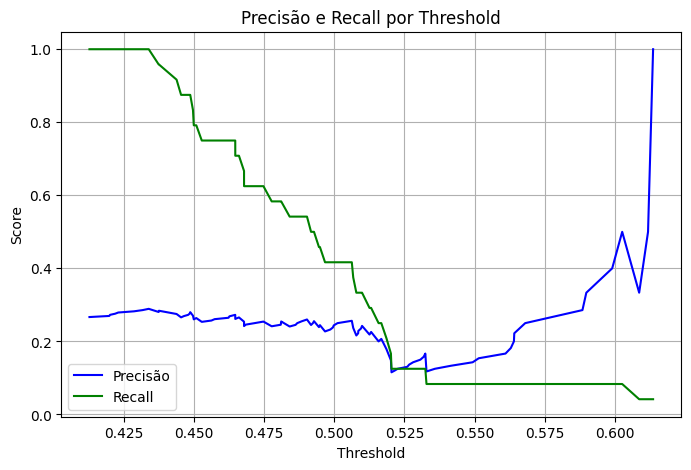

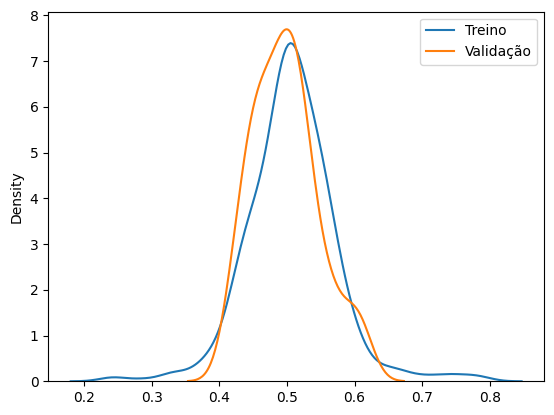

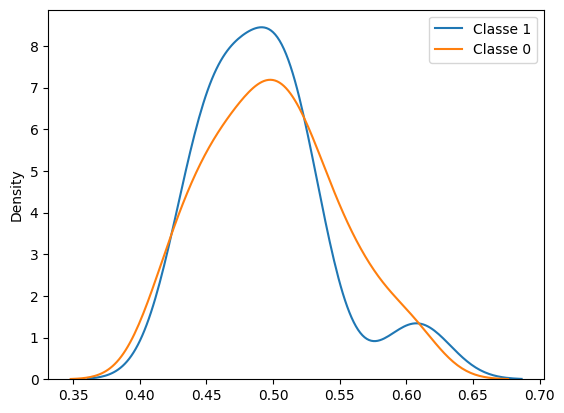

In [18]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [19]:
from sklearn.metrics import f1_score
f1 = f1_score(y_true, y_pred)
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.3125


# LGBM GOOGLE

## Versão com early stopping

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 15,
            'max_depth': -1, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 
            'verbose': -1  # Silencia o output do LightGBM

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [44]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.3, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 339 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 144 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 46, number of negative: 293
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000462 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7439
[LightGBM] [Info] Number of data points in the train set: 339, number of used features: 72
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.857
AUC na validação: 0.554
Diferença AUC (Treino - Validação): 0.303
PROVÁVEL OVERFITTING
PR AUC no treino: 0.619
PR AUC na validação: 0.374
Diferença PR AUC (Treino - Validação): 0.246
F1 Score no treino: 0.411
F1 Score na validação: 0.156


(np.float64(0.8574329576176128),
 np.float64(0.5542617955372964),
 np.float64(0.30317116208031647),
 np.float64(0.6194367318837503),
 np.float64(0.3738194311172103),
 np.float64(0.41147231135968826),
 np.float64(0.15637623231010025))

Avaliar e logar modelo
MLflow Run ID: 4ba8bab05e3f428e823f49702b741886 para BBDC4.SA_20dias_x_0.04val_6dias_alvo
AUC no treino: 0.859
AUC na validação: 0.544

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.857
  Precisão média (em 178 janelas com previsão positiva): 0.975
  Recall médio: 0.260

Calibrando thresholds para precisão mínima de 0.65...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 97.48%
  Recall Médio Esperado: 26.05%
  Janelas Usadas para Precisão: 178.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 45 janelas com previsão positiva): 0.388
Recall médio: 0.112
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 8
Modelo BBDC4.SA_20dias_x_0.04val_6dias_alvo salvo na run 4ba8bab05e3f428e823f49702b741886


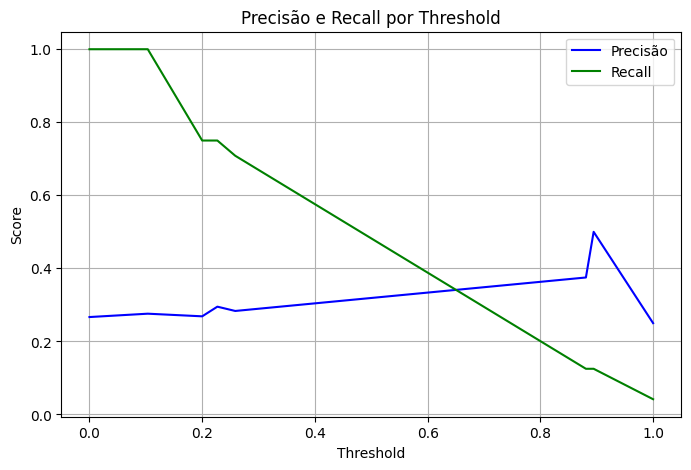

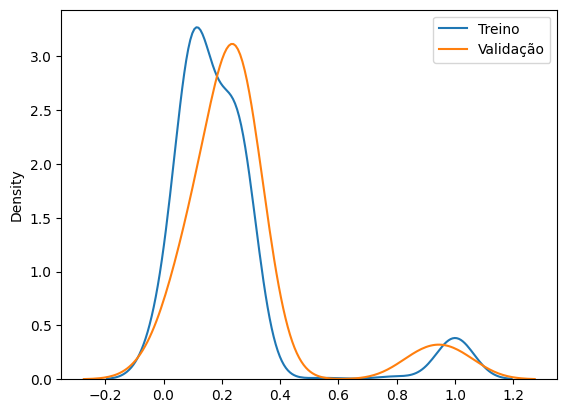

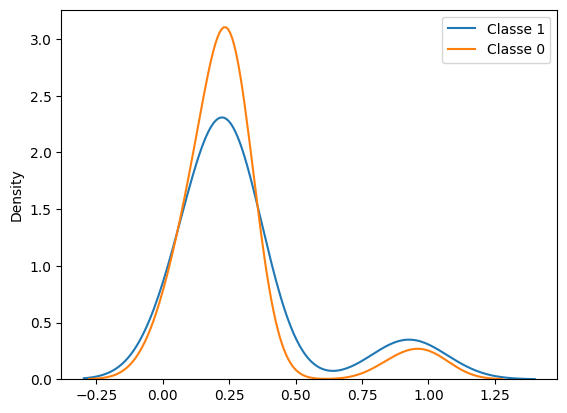

In [45]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [19]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


adc_atr_pct_ultimo_SANB11             441.914847
adc_close_trend_BBAS3                 437.551800
macd_signal_std_norm_atr_principal    139.820301
adc_rsi_ultimo_ITUB4                   89.520600
adc_ret_acum_BBAS3                     86.048005
retorno_desde_mudanca_close            84.056400
adc_close_trend_SANB11                 72.630599
adc_atr_pct_mean_geral_ultimo          67.913560
tr_pct_mean                            45.610310
adc_macd_hist_ultimo_ITUB4             30.382000
volume_mean                            20.646674
adc_ret_acum_SANB11                    17.307870
correl_papel_ibov                      16.297100
retorno_std                            11.043500
beta_papel_ibov                        10.130400
dtype: float64

In [20]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 120 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 56, number of negative: 307
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000087 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 608
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Early stopping, best iteration is:
[186]	valid_0's auc: 0.638822	valid_0's binary_logloss: 0.565274
Treinamento LGBM concluído. Melhor iteração: 186

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (120 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Su

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

... (240 outputs left out)

[LightGBM] [Info] Number of positive: 56, number of negative: 307
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000370 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5672
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 50
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Info] Number of positive: 56, number of negative: 307
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000320 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5672
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 50
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

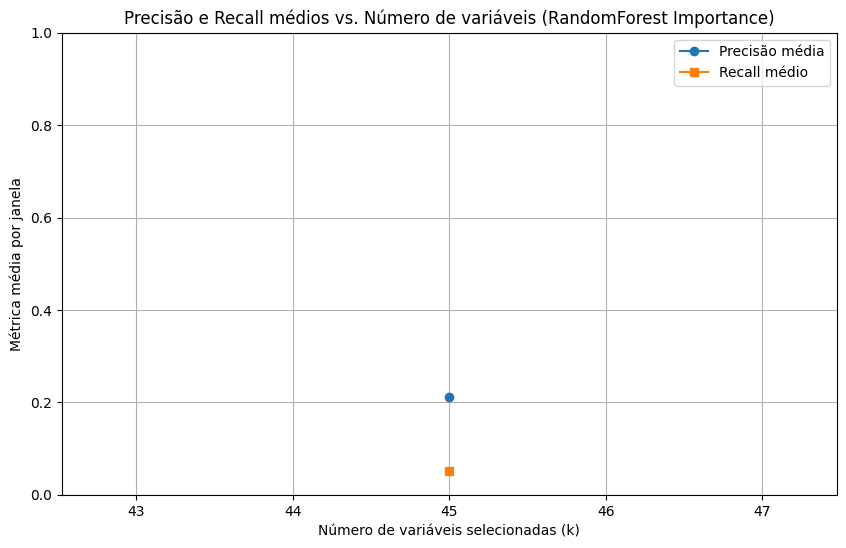

In [21]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

In [22]:
y_validacao.sum()

np.float64(24.0)

# Features reduzidas

In [23]:
n_features = 45
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['adc_atr_pct_ultimo_SANB11',
 'adc_close_trend_BBAS3',
 'macd_signal_std_norm_atr_principal',
 'adc_rsi_ultimo_ITUB4',
 'adc_ret_acum_BBAS3',
 'retorno_desde_mudanca_close',
 'adc_close_trend_SANB11',
 'adc_atr_pct_mean_geral_ultimo',
 'tr_pct_mean',
 'adc_macd_hist_ultimo_ITUB4',
 'volume_mean',
 'adc_ret_acum_SANB11',
 'correl_papel_ibov',
 'retorno_std',
 'beta_papel_ibov',
 'volume_std',
 'macd_hist_ultimo_norm_atr_principal',
 'dolar_ultimo',
 'close_dist_min',
 'adc_close_mean_geral_ultimo',
 'close_trend',
 'close_vs_mm20',
 'volume_trend',
 'retorno_medio_pos',
 'retorno_acumulado',
 'mm5_vs_mm20',
 'macd_hist_std',
 'macd_hist_mean',
 'close_amplitude',
 'close_min',
 'atr_ultimo',
 'macd_std_norm_atr_principal',
 'rsi_ultimo',
 'rsi_std',
 'rsi_mean',
 'atr_pct_ultimo',
 'retorno_medio_neg',
 'dias_queda_pct',
 'dias_alta_pct',
 'tr_pct_ultimo',
 'close_amplitude_norm_atr_principal',
 'tr_ultimo_norm_atr_principal',
 'tr_pct_std',
 'tr_std_norm_atr_principal',
 'macd_signal_

In [24]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [29]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.35, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit',
    metodo_calibracao='isotonic'
    , class_weight={0: 3, 1: 1} # Aumenta o peso da classe minoritária (1) para melhorar recall
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 314 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 169 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 46, number of negative: 268
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000339 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4361
[LightGBM] [Info] Number of data points in the train set: 314, number of used features: 45
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.054118 -> initscore=-2.860958
[LightGBM] [Info] Start training from score -2.860958
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.823
AUC na validação: 0.573
Diferença AUC (Treino - Validação): 0.250
PROVÁVEL OVERFITTING
PR AUC no treino: 0.560
PR AUC na validação: 0.378
Diferença PR AUC (Treino - Validação): 0.182
F1 Score no treino: 0.310
F1 Score na validação: 0.111


(np.float64(0.8228137870265522),
 np.float64(0.5725149547157611),
 np.float64(0.2502988323107911),
 np.float64(0.5600581578024328),
 np.float64(0.37791797190322685),
 np.float64(0.3095088051345814),
 np.float64(0.11076476279364164))

Avaliar e logar modelo
MLflow Run ID: 169137bd258d440a90ffe589b4013c50 para BBDC4.SA_20dias_x_0.04val_6dias_alvo
AUC no treino: 0.837
AUC na validação: 0.567

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.823
  Precisão média (em 199 janelas com previsão positiva): 0.728
  Recall médio: 0.209

Calibrando thresholds para precisão mínima de 0.60...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 72.80%
  Recall Médio Esperado: 20.90%
  Janelas Usadas para Precisão: 199.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 45 janelas com previsão positiva): 0.312
Recall médio: 0.075
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 7
Modelo BBDC4.SA_20dias_x_0.04val_6dias_alvo salvo na run 169137bd258d440a90ffe589b4013c50


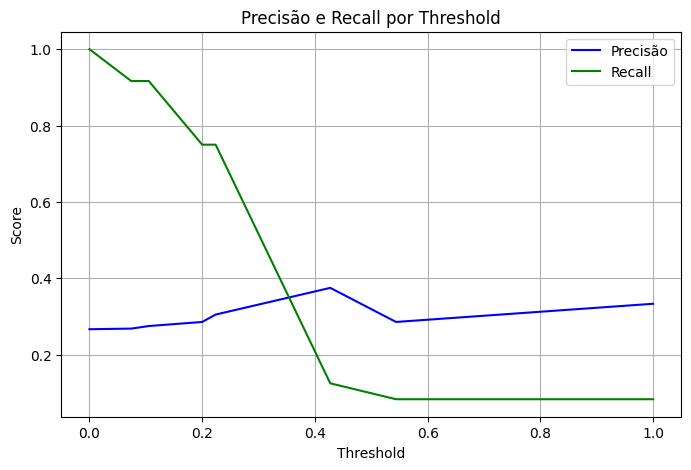

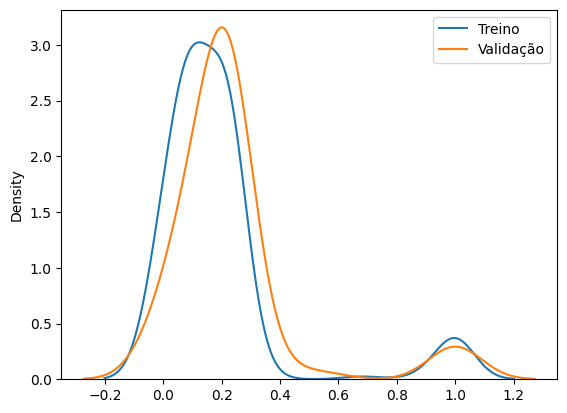

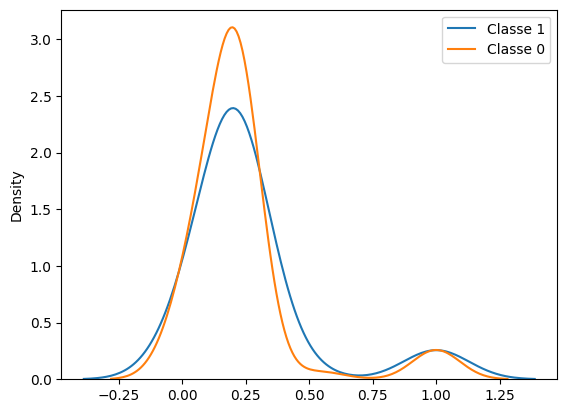

In [30]:
precisao_minima = 0.6
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

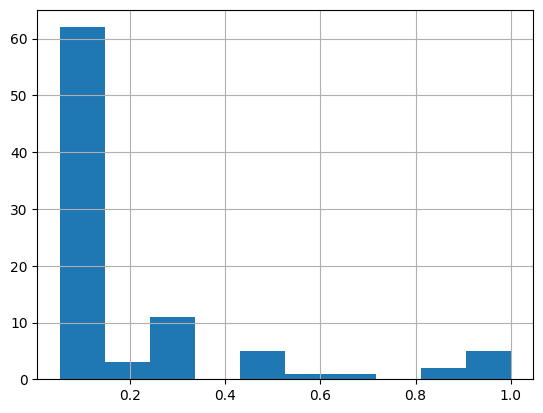

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.254036
std       0.237498
min       0.052632
25%       0.140000
50%       0.140000
75%       0.333333
max       1.000000
dtype: float64